In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [6]:
# Load CSV
train_df = pd.read_csv('/kaggle/input/datasets/phucthaiv02/butterfly-image-classification/Training_set.csv')

print("Train shape:", train_df.shape)
print("\nTrain columns:", train_df.columns.tolist())
print("\nSample train data:")
train_df.head()

Train shape: (6499, 2)

Train columns: ['filename', 'label']

Sample train data:


,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART


Jumlah kelas (spesies kupu-kupu): 75


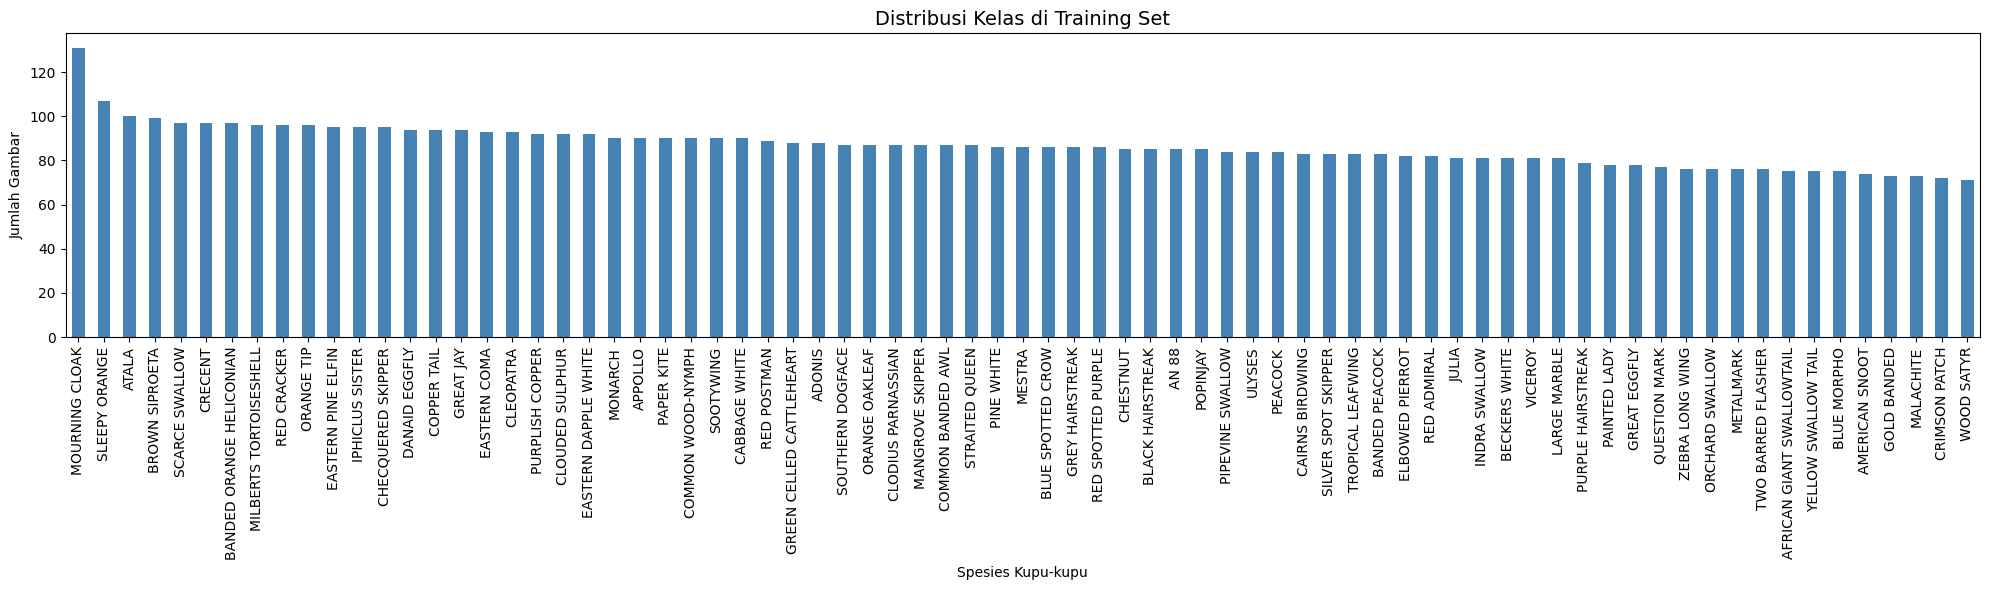

In [7]:
# Jumlah kelas
num_classes = train_df['label'].nunique()
print(f"Jumlah kelas (spesies kupu-kupu): {num_classes}")

# Plot distribusi
plt.figure(figsize=(20, 6))
train_df['label'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Distribusi Kelas di Training Set', fontsize=14)
plt.xlabel('Spesies Kupu-kupu')
plt.ylabel('Jumlah Gambar')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [8]:
# Path ke folder gambar
train_dir = '/kaggle/input/datasets/phucthaiv02/butterfly-image-classification/train'
# Tambahkan kolom path lengkap
train_df['filename'] = train_df['filename'].astype(str)

# Parameter gambar
IMG_SIZE   = (128, 128)
BATCH_SIZE = 32

# Data augmentation untuk training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2   # 20% untuk validasi
)

# Validasi: hanya rescale
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# Generator training
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42
)

# Generator validasi
val_generator = val_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

print(f"\nJumlah training samples : {train_generator.n}")
print(f"Jumlah validation samples: {val_generator.n}")
print(f"Jumlah kelas             : {len(train_generator.class_indices)}")

Found 5200 validated image filenames belonging to 75 classes.
Found 1299 validated image filenames belonging to 75 classes.

Jumlah training samples : 5200
Jumlah validation samples: 1299
Jumlah kelas             : 75


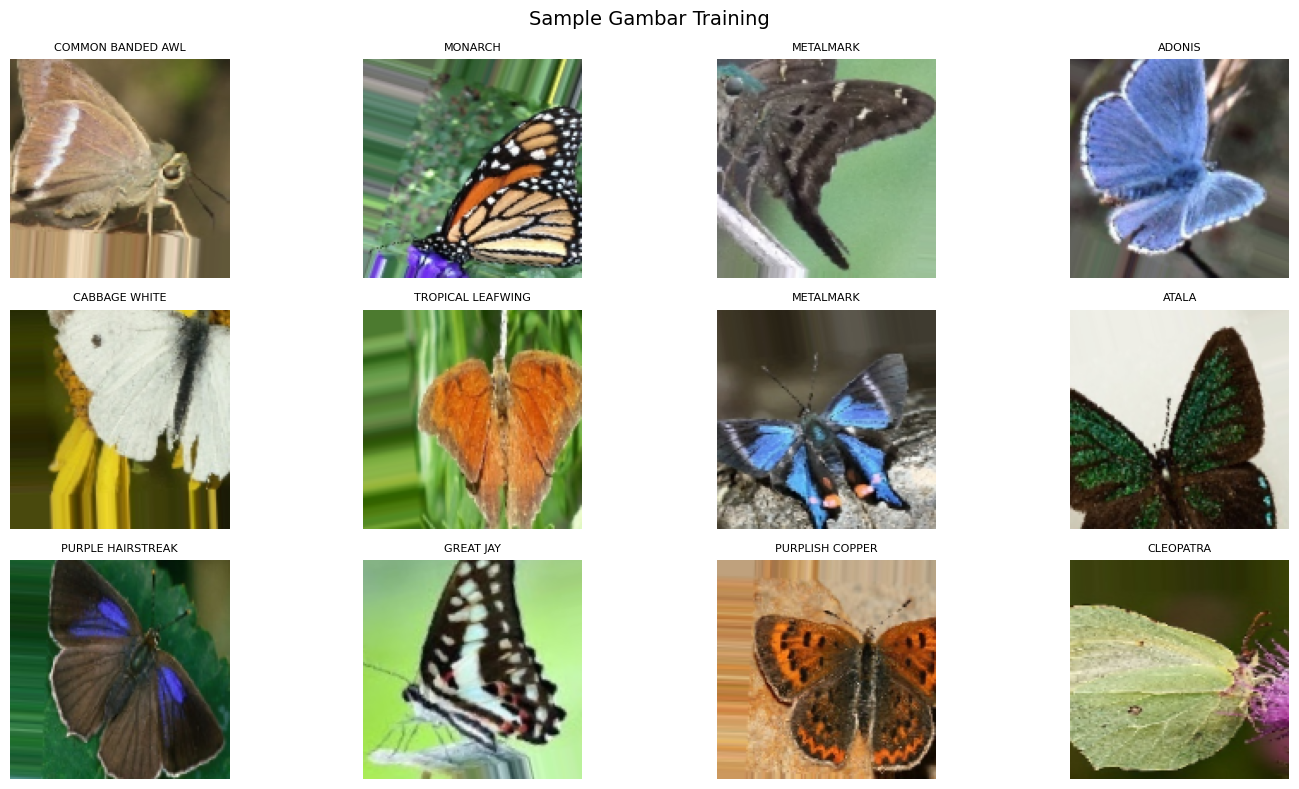

In [9]:
# Ambil 1 batch
images, labels = next(train_generator)

# Nama kelas
class_names = list(train_generator.class_indices.keys())

plt.figure(figsize=(15, 8))
for i in range(12):
    plt.subplot(3, 4, i+1)
    plt.imshow(images[i])
    plt.title(class_names[np.argmax(labels[i])], fontsize=8)
    plt.axis('off')
plt.suptitle('Sample Gambar Training', fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
def build_simple_cnn(input_shape, num_classes):
    model = keras.Sequential([
        # --- Block 1 ---
        layers.Conv2D(32, (3,3), activation='relu', padding='same',
                      input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # --- Block 2 ---
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # --- Block 3 ---
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # --- Classifier ---
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name='Simple_CNN')

    return model

# Build model
model = build_simple_cnn(
    input_shape=(*IMG_SIZE, 3),
    num_classes=len(train_generator.class_indices)
)

# Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

I0000 00:00:1775138441.392518      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1775138441.398662      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75)             │         9,675 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,492,523 (17.14 MB)

 Trainable params: 4,491,819 (17.13 MB)

 Non-trainable params: 704 (2.75 KB)

In [11]:
# Callbacks
callbacks = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

# Train
EPOCHS = 30

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

print("\n✅ Training selesai!")

Epoch 1/30


I0000 00:00:1775138448.098913     131 service.cc:152] XLA service 0x7ec3bc005470 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775138448.098950     131 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1775138448.098954     131 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1775138448.940141     131 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-02 14:00:52.090364: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-02 14:00:52.243794: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-02 14:00:53.646620: E external/local_xl

  2/163 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.0234 - loss: 5.2807 

I0000 00:00:1775138460.215661     131 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 36/163 ━━━━━━━━━━━━━━━━━━━━ 1:26 684ms/step - accuracy: 0.0272 - loss: 4.8817

2026-04-02 14:01:26.810997: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-02 14:01:26.960293: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-02 14:01:27.763747: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-02 14:01:28.040509: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


163/163 ━━━━━━━━━━━━━━━━━━━━ 149s 820ms/step - accuracy: 0.0402 - loss: 4.4686 - val_accuracy: 0.0216 - val_loss: 4.8268 - learning_rate: 0.0010
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 198ms/step - accuracy: 0.1431 - loss: 3.4732 - val_accuracy: 0.0570 - val_loss: 4.3870 - learning_rate: 0.0010
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 33s 199ms/step - accuracy: 0.2033 - loss: 3.0620 - val_accuracy: 0.2633 - val_loss: 2.8660 - learning_rate: 0.0010
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 33s 199ms/step - accuracy: 0.2715 - loss: 2.7626 - val_accuracy: 0.4018 - val_loss: 2.2235 - learning_rate: 0.0010
Epoch 5/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 196ms/step - accuracy: 0.3114 - loss: 2.5525 - val_accuracy: 0.3841 - val_loss: 2.2532 - learning_rate: 0.0010
Epoch 6/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 198ms/step - accuracy: 0.3483 - loss: 2.4161 - val_accuracy: 0.4018 - val_loss: 2.2365 - learning_rate: 0.0010
Epoch 7/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 34s 206ms/step - accuracy: 0.4006 - loss

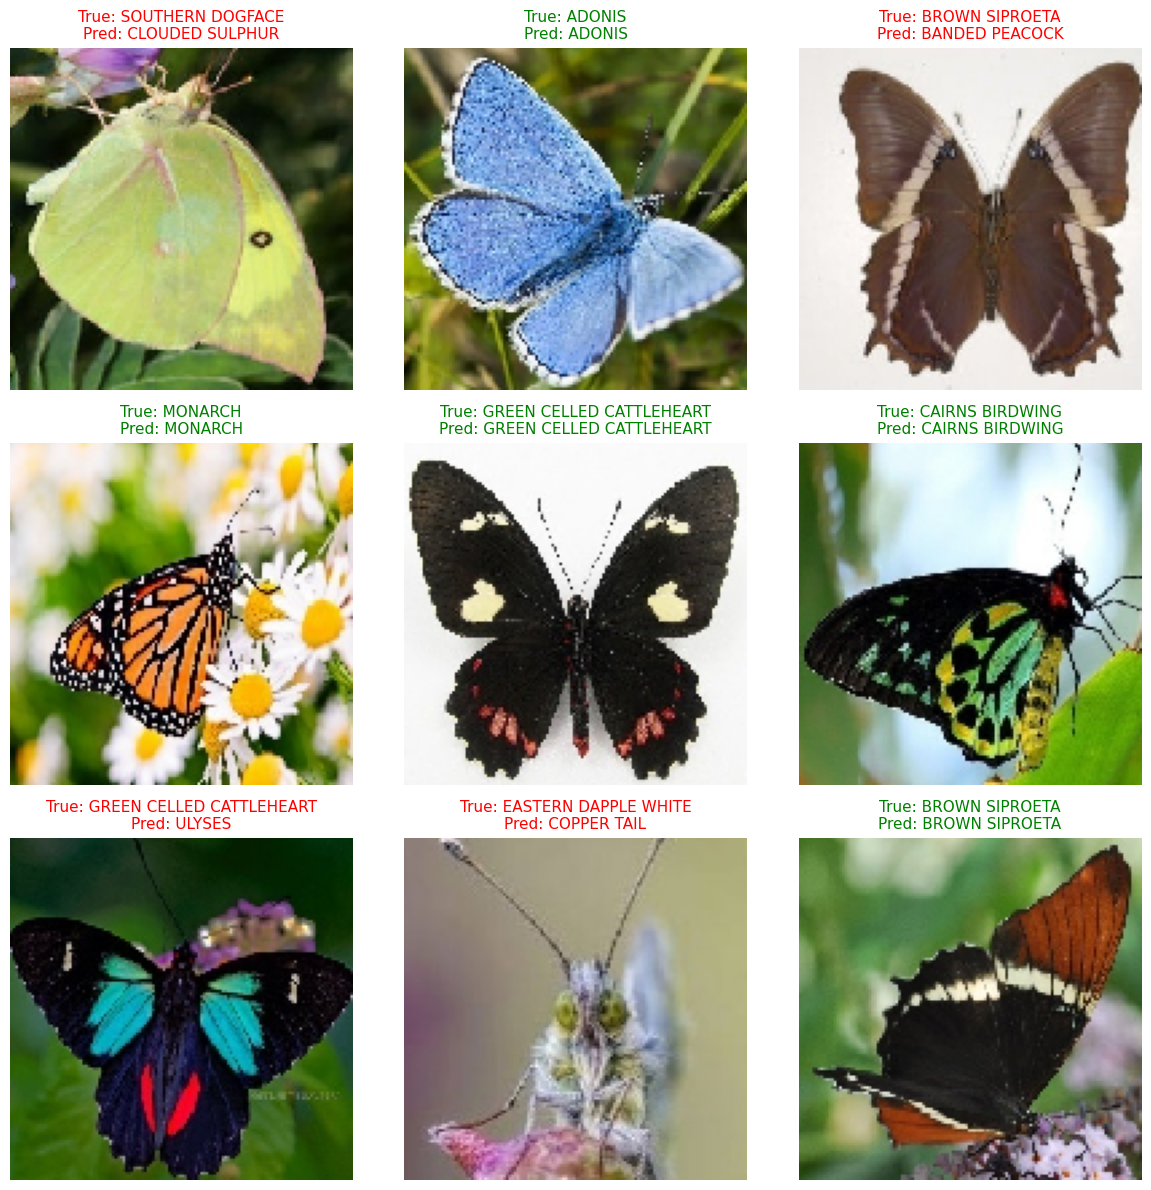

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Mengambil satu batch data dari val_generator
val_images, val_labels = next(iter(val_generator))

# Melakukan prediksi pada batch tersebut
val_preds = model.predict(val_images, verbose=0)

# Mendapatkan indeks kelas asli dan hasil prediksi
true_classes = np.argmax(val_labels, axis=1) if val_labels.ndim > 1 else val_labels
pred_classes = np.argmax(val_preds, axis=1)

# Memetakan indeks ke nama kelas
class_names = list(val_generator.class_indices.keys())

# Membuat visualisasi grid 3x3 untuk 9 gambar pertama
plt.figure(figsize=(12, 12))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    
    # Menampilkan gambar (penyesuaian rentang pixel jika diperlukan)
    img = val_images[i]
    if img.max() > 1.0:
        img = img / 255.0
    plt.imshow(img)
    
    true_label = class_names[true_classes[i]]
    pred_label = class_names[pred_classes[i]]
    
    # Teks berwarna hijau jika prediksi benar, merah jika salah
    text_color = 'green' if true_label == pred_label else 'red'
    
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=text_color, fontsize=11)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
model.save('butterfly_cnn_model.keras')
print("✅ Model tersimpan sebagai butterfly_cnn_model.keras")

model.save('butterfly_cnn_model.h5')
print("✅ Model tersimpan sebagai butterfly_cnn_model.h5")

import json
with open('class_indices.json', 'w') as f:
    json.dump(train_generator.class_indices, f)
print("✅ Class indices tersimpan sebagai class_indices.json")

import os
for f in ['butterfly_cnn_model.keras', 'butterfly_cnn_model.h5', 'class_indices.json']:
    size = os.path.getsize(f) / (1024*1024)
    print(f"📁 {f} → {size:.2f} MB")

✅ Model tersimpan sebagai butterfly_cnn_model.keras
✅ Model tersimpan sebagai butterfly_cnn_model.h5
✅ Class indices tersimpan sebagai class_indices.json
📁 butterfly_cnn_model.keras → 51.50 MB
📁 butterfly_cnn_model.h5 → 51.51 MB
📁 class_indices.json → 0.00 MB


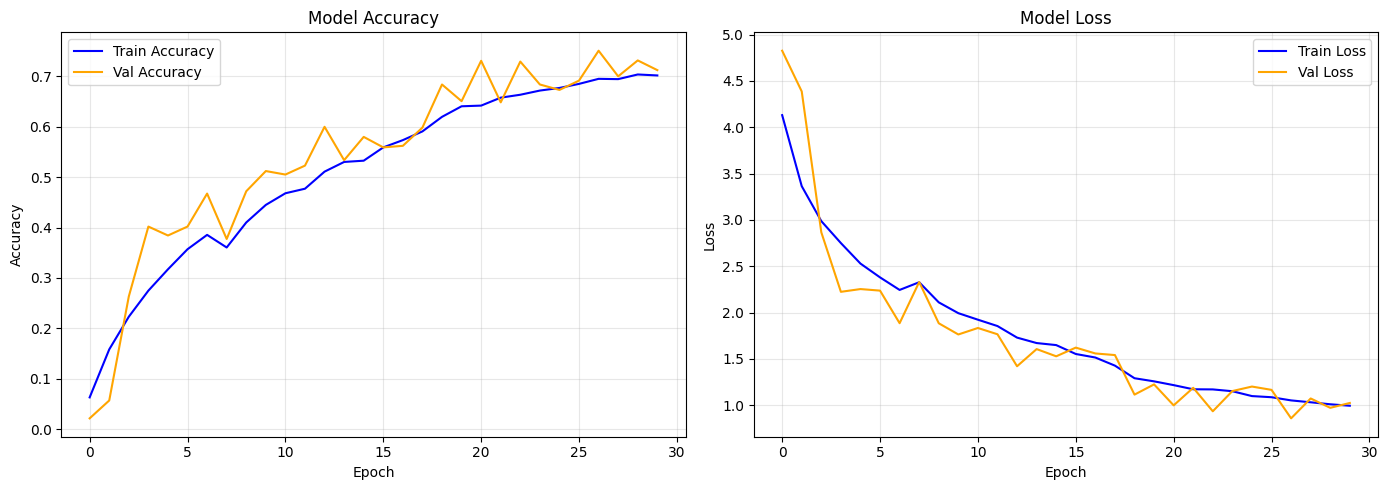


🏆 Best Validation Accuracy: 0.7506 (75.06%)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'],     label='Train Accuracy', color='blue')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy',   color='orange')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history.history['loss'],     label='Train Loss', color='blue')
axes[1].plot(history.history['val_loss'], label='Val Loss',   color='orange')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Best val accuracy
best_acc = max(history.history['val_accuracy'])
print(f"\n🏆 Best Validation Accuracy: {best_acc:.4f} ({best_acc*100:.2f}%)")